Alternative scenario 3: New terminal

In [1]:
# New terminal: capacity 650k -> 800k tons/day, demand unchanged
# Given N(T) = n, arrival times are iid Uniform(0, T) -> vessel goes to day floor(time)

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# parameters and functions from the basic scenario
params = {
    'Container': {'lam': 5.5812, 'mu': 9.6069, 'sigma': 0.3493},
    'Tanker': {'lam': 2.2299, 'mu': 10.9119, 'sigma': 0.2963},
    'Bulk': {'lam': 2.2947, 'mu': 10.4989, 'sigma': 0.3806},
}
days_in_year = 365
types = ['Container', 'Tanker', 'Bulk']
shift = np.log(1.10)    # larger vessels scenario

def simPoissonProcess(lam, t, rng):
    intArrivalTimsDist = stats.expon(scale=1/lam)
    Nt = 0
    time = intArrivalTimsDist.rvs(random_state=rng)
    while time < t:
        Nt += 1
        time += intArrivalTimsDist.rvs(random_state=rng)
    return Nt

def EX(mu, sigma):
    return np.exp(mu + sigma**2 / 2)

def EX2(mu, sigma):
    return np.exp(2 * mu + 2 * sigma**2)



capacity_old = 650000
capacity_new = 800000

nr_runs_daily = 2000                      # 730,000 days
rng_terminal = np.random.default_rng(42)

cargo_dist = {t: stats.lognorm(s=params[t]['sigma'], scale=np.exp(params[t]['mu']))
              for t in ['Container', 'Tanker', 'Bulk']}
arrival_time_dist = stats.uniform(loc=0, scale=days_in_year)

daily_S = np.zeros((nr_runs_daily, days_in_year))   # total cargo per day

for r in range(nr_runs_daily):
    for t in ['Container', 'Tanker', 'Bulk']:
        n = simPoissonProcess(params[t]['lam'], days_in_year, rng_terminal)
        arrival_times = arrival_time_dist.rvs(size=n, random_state=rng_terminal)
        cargo = cargo_dist[t].rvs(size=n, random_state=rng_terminal)
        day = np.floor(arrival_times).astype(int)
        daily_S[r] += np.bincount(day, weights=cargo, minlength=days_in_year)

print('simulated days:', daily_S.size)
print('mean daily throughput:', round(daily_S.mean()), ' std:', round(daily_S.std(ddof=1)))

simulated days: 730000
mean daily throughput: 305863  std: 116669


In [2]:
# Check vs theory (compound Poisson, t = 1 day)
theo_mean_day = sum(params[t]['lam'] * EX(params[t]['mu'], params[t]['sigma']) for t in types)
theo_std_day = np.sqrt(sum(params[t]['lam'] * EX2(params[t]['mu'], params[t]['sigma']) for t in types))
print(f"daily mean: simulated = {daily_S.mean():,.0f}, theoretical = {theo_mean_day:,.0f}")
print(f"daily std:  simulated = {daily_S.std(ddof=1):,.0f}, theoretical = {theo_std_day:,.0f}")

daily mean: simulated = 305,863, theoretical = 305,430
daily std:  simulated = 116,669, theoretical = 116,610


In [3]:
# Congestion statistics for a given capacity (95% CI as in lesson 5)
def congestion_stats(daily, capacity):
    exceed = daily > capacity
    p = exceed.mean()
    half_width = 1.96 * exceed.std(ddof=1) / np.sqrt(exceed.size)
    days_per_year = exceed.sum(axis=1)
    return {
        'P(day > capacity)': p,
        'CI low': p - half_width,
        'CI high': p + half_width,
        'Congestion days/year (mean)': days_per_year.mean(),
        'Congestion days/year (95% quantile)': np.percentile(days_per_year, 95),
        'P(no congestion in a year)': np.mean(days_per_year == 0),
        'Days between congestion days': 1 / p if p > 0 else np.inf,
    }

# Larger vessels: mu + log(1.10) scales each cargo by 1.10
daily_S_larger = daily_S * np.exp(shift)

rows = []
for name, daily, cap in [('Basic, 650k',                     daily_S,        capacity_old),
                         ('New terminal, 800k',              daily_S,        capacity_new),
                         ('Larger vessels, 650k',            daily_S_larger, capacity_old),
                         ('Larger vessels + terminal, 800k', daily_S_larger, capacity_new)]:
    rows.append({'Scenario': name, **congestion_stats(daily, cap)})

terminal_table = pd.DataFrame(rows)
print(terminal_table.to_string(index=False, float_format='{:,.5f}'.format))

                       Scenario  P(day > capacity)  CI low  CI high  Congestion days/year (mean)  Congestion days/year (95% quantile)  P(no congestion in a year)  Days between congestion days
                    Basic, 650k            0.00573 0.00556  0.00590                      2.09150                              5.00000                     0.13000                     174.51590
             New terminal, 800k            0.00029 0.00025  0.00033                      0.10700                              1.00000                     0.89650                   3,411.21495
           Larger vessels, 650k            0.01555 0.01527  0.01584                      5.67750                             10.00000                     0.00400                      64.28886
Larger vessels + terminal, 800k            0.00130 0.00122  0.00139                      0.47600                              2.00000                     0.62850                     766.80672


In [4]:
# Busiest day of each year vs old and new capacity
max_day = daily_S.max(axis=1)
max_day_larger = daily_S_larger.max(axis=1)

for name, m in [('Basic', max_day), ('Larger vessels', max_day_larger)]:
    print(f"{name}: busiest day mean = {m.mean():,.0f}, 95% quantile = {np.percentile(m, 95):,.0f}, "
          f"P(busiest day > 650k) = {np.mean(m > capacity_old):.3f}, "
          f"P(busiest day > 800k) = {np.mean(m > capacity_new):.3f}")

Basic: busiest day mean = 715,896, 95% quantile = 831,518, P(busiest day > 650k) = 0.870, P(busiest day > 800k) = 0.103
Larger vessels: busiest day mean = 787,486, 95% quantile = 914,669, P(busiest day > 650k) = 0.996, P(busiest day > 800k) = 0.371


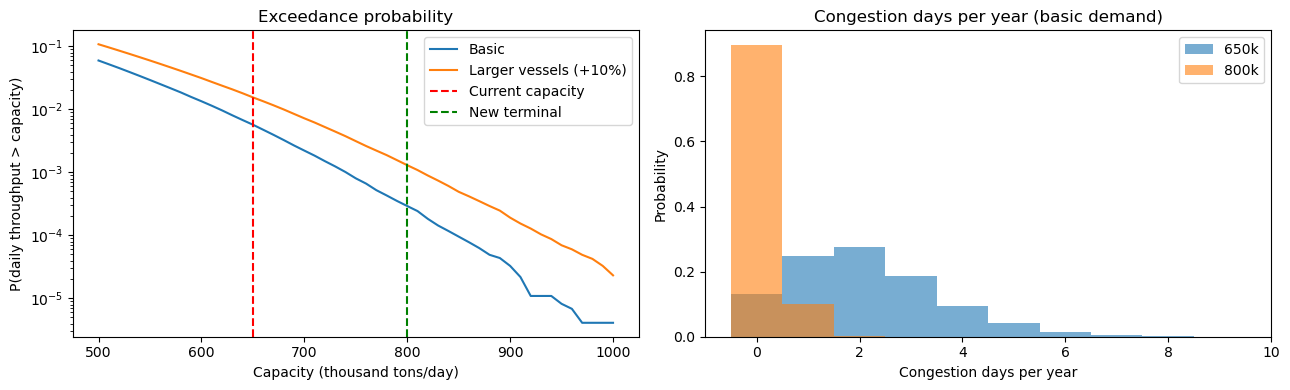

In [5]:
# Exceedance probability vs capacity, and congestion days per year
import matplotlib.pyplot as plt

capacities = np.arange(500000, 1000001, 10000)
p_basic = [np.mean(daily_S > c) for c in capacities]
p_larger = [np.mean(daily_S_larger > c) for c in capacities]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].semilogy(capacities / 1e3, p_basic, label='Basic')
ax[0].semilogy(capacities / 1e3, p_larger, label='Larger vessels (+10%)')
ax[0].axvline(650, color='r', ls='--', label='Current capacity')
ax[0].axvline(800, color='g', ls='--', label='New terminal')
ax[0].set_xlabel('Capacity (thousand tons/day)')
ax[0].set_ylabel('P(daily throughput > capacity)')
ax[0].set_title('Exceedance probability')
ax[0].legend()

days_old = (daily_S > capacity_old).sum(axis=1)
days_new = (daily_S > capacity_new).sum(axis=1)
bins = np.arange(-0.5, days_old.max() + 1.5)
ax[1].hist(days_old, bins=bins, density=True, alpha=0.6, label='650k')
ax[1].hist(days_new, bins=bins, density=True, alpha=0.6, label='800k')
ax[1].set_xlabel('Congestion days per year')
ax[1].set_ylabel('Probability')
ax[1].set_title('Congestion days per year (basic demand)')
ax[1].legend()
plt.tight_layout()
plt.show()

In [6]:
# Throughput level exceeded once a year / once every 10 years
for name, daily in [('Basic', daily_S), ('Larger vessels', daily_S_larger)]:
    once_a_year = np.quantile(daily, 1 - 1 / days_in_year)
    once_a_decade = np.quantile(daily, 1 - 1 / (10 * days_in_year))
    print(f"{name}: exceeded once a year = {once_a_year:,.0f}, once every 10 years = {once_a_decade:,.0f}")

Basic: exceeded once a year = 688,811, once every 10 years = 802,587
Larger vessels: exceeded once a year = 757,692, once every 10 years = 882,845
